In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.multitest import multipletests

In [3]:
sites = {"St.David": 7, "Contention": 6, "Fairbank": 1, "Boquillas": 8, "CharlestonMesquite": 2, "Moson": 3, "Hunter": 4, "Hereford": 5}
seasons = {1: "Cool-Season Recharge", 2: "Pre-Monsoon Dry", 3: "Monsoon", 4: "Post-Monsoon Recession"}
perennial = [1, 2, 4, 6, 7]
example = 1
alpha = 0.05

def season(month):
    if month in [12, 1, 2, 3]:
        return 1
    if month in [4, 5, 6]:
        return 2
    if month in [7, 8, 9]:
        return 3
    return 4

gf = pd.read_csv("../Data/SPRNCAPredFP.csv", parse_dates = ["date"])
gf["Camera"] = gf["site"].map(sites)
gf["WY"] = gf["date"].dt.year + (gf["date"].dt.month >= 10)
gf["Season"] = gf["date"].dt.month.map(season)
gf = gf[gf["Camera"].isin(perennial) & gf["WY"].between(2007, 2025)].dropna(subset = ["fp_final"])

seasonal = (
    gf.groupby(["Camera", "WY", "Season"])
    .agg(FP = ("fp_final", "mean"), days = ("fp_final", "size"))
    .reset_index()
)
year_mean = seasonal["WY"].mean()
seasonal["year_c"] = seasonal["WY"] - year_mean

weights = seasonal.groupby("Season")["days"].mean()
weights = weights / weights.sum()

annual = gf.groupby(["Camera", "WY"])["fp_final"].mean().rename("FP").reset_index()

In [4]:
formula = "FP ~ 0 + C(Camera):C(Season) + C(Camera):C(Season):year_c"
model = smf.ols(formula, data = seasonal).fit(cov_type = "cluster", cov_kwds = {"groups": seasonal["WY"]}, use_t = True)
n_clusters = seasonal["WY"].nunique()

def contrasts(cameras):
    L = pd.DataFrame(0.0, index = list(seasons), columns = model.params.index)
    for s in seasons:
        for c in cameras:
            L.loc[s, f"C(Camera)[{c}]:C(Season)[{s}]:year_c"] = 1 / len(cameras)
    L.loc["Annual"] = weights.to_numpy() @ L.to_numpy()
    return L.loc[["Annual"] + list(seasons)]

def decompose(cameras):
    L = contrasts(cameras)
    test = model.t_test(L.to_numpy())
    ci = test.conf_int(alpha)
    out = pd.DataFrame(
        {"beta": test.effect, "se": test.sd.ravel(), "lower": ci[:, 0], "upper": ci[:, 1], "p": test.pvalue.ravel()},
        index = L.index
    )
    S = L.loc[list(seasons)].to_numpy()
    b = out.loc[list(seasons), "beta"].to_numpy()
    V = S @ model.cov_params().to_numpy() @ S.T
    w = weights.to_numpy()
    share = w * b / (w @ b)
    G = (np.diag(w) - np.outer(share, w)) / (w @ b)
    out["share"] = np.r_[1.0, share]
    out["share_se"] = np.r_[0.0, np.sqrt(np.diag(G @ V @ G.T))]
    return out

effects = pd.concat(
    {"Average": decompose(perennial), **{f"C{c}": decompose([c]) for c in perennial}},
    names = ["Model", "Season"]
)

def hierarchical(models):
    annual = effects.loc[[(m, "Annual") for m in models], "p"]
    annual_adj = pd.Series(multipletests(annual, method = "fdr_bh")[1], index = models)
    selected = annual_adj.index[annual_adj < alpha]
    scale = len(models) / max(len(selected), 1)
    for m in models:
        effects.loc[(m, "Annual"), "p_adj"] = annual_adj[m]
        if m in selected:
            seasonal = effects.loc[[(m, s) for s in seasons], "p"]
            effects.loc[[(m, s) for s in seasons], "p_adj"] = np.minimum(multipletests(seasonal, method = "fdr_bh")[1] * scale, 1)

effects["p_adj"] = np.nan
hierarchical(["Average"])
hierarchical([f"C{c}" for c in perennial])
effects.round(4)

beta      se   lower   upper       p   share  share_se  \
Model   Season                                                             
Average Annual -0.0179  0.0054 -0.0292 -0.0066  0.0038  1.0000    0.0000   
        1      -0.0179  0.0075 -0.0336 -0.0023  0.0272  0.3329    0.0565   
        2      -0.0122  0.0053 -0.0233 -0.0011  0.0335  0.1696    0.0438   
        3      -0.0190  0.0088 -0.0374 -0.0006  0.0437  0.2680    0.1460   
        4      -0.0246  0.0135 -0.0529  0.0038  0.0858  0.2295    0.0759   
C1      Annual -0.0154  0.0047 -0.0253 -0.0056  0.0041  1.0000    0.0000   
        1      -0.0043  0.0020 -0.0085 -0.0000  0.0480  0.0919    0.0228   
        2      -0.0129  0.0064 -0.0264  0.0006  0.0595  0.2090    0.0867   
        3      -0.0252  0.0118 -0.0500 -0.0003  0.0476  0.4109    0.1785   
        4      -0.0266  0.0177 -0.0638  0.0106  0.1500  0.2882    0.1507   
C2      Annual -0.0076  0.0025 -0.0129 -0.0023  0.0072  1.0000    0.0000   
        1      -0.0000  0.0000 -0.0000 -0.0000  0.0268  0.0000    0.0000   
        2      -0.0048  0.0042 -0.0135  0.0040  0.2673  0.1563    0.1375   
        3      -0.0125  0.0097 -0.0330  0.0079  0.2141  0.4158    0.2678   
        4      -0.0194  0.0086 -0.0374 -0.0015  0.0355  0.4278    0.1469   
C4      Annual -0.0144  0.0050 -0.0250 -0.0038  0.0103  1.0000    0.0000   
        1      -0.0146  0.0066 -0.0284 -0.0009  0.0386  0.3376    0.0704   
        2      -0.0094  0.0058 -0.0216  0.0028  0.1242  0.1624    0.1058   
        3      -0.0031  0.0039 -0.0113  0.0051  0.4396  0.0540    0.0660   
        4      -0.0385  0.0160 -0.0720 -0.0049  0.0270  0.4459    0.0573   
C6      Annual -0.0266  0.0081 -0.0435 -0.0097  0.0040  1.0000    0.0000   
        1      -0.0363  0.0153 -0.0684 -0.0042  0.0289  0.4528    0.0746   
        2      -0.0202  0.0079 -0.0369 -0.0036  0.0197  0.1895    0.0497   
        3      -0.0254  0.0105 -0.0475 -0.0033  0.0264  0.2404    0.1214   
        4      -0.0187  0.0193 -0.0592  0.0218  0.3450  0.1173    0.1065   
C7      Annual -0.0253  0.0102 -0.0468 -0.0039  0.0231  1.0000    0.0000   
        1      -0.0344  0.0158 -0.0676 -0.0012  0.0432  0.4508    0.0793   
        2      -0.0135  0.0141 -0.0432  0.0162  0.3522  0.1328    0.0891   
        3      -0.0289  0.0104 -0.0507 -0.0071  0.0122  0.2873    0.1637   
        4      -0.0196  0.0184 -0.0582  0.0190  0.3004  0.1292    0.0896   

                 p_adj  
Model   Season          
Average Annual  0.0188  
        1       0.0547  
        2       0.0547  
        3       0.0547  
        4       0.0858  
C1      Annual  0.0102  
        1       0.0873  
        2       0.0991  
        3       0.0873  
        4       0.2143  
C2      Annual  0.0120  
        1       0.0873  
        2       0.3342  
        3       0.2854  
        4       0.0873  
C4      Annual  0.0129  
        1       0.0873  
        2       0.1911  
        3       0.4396  
        4       0.0873  
C6      Annual  0.0102  
        1       0.0873  
        2       0.0873  
        3       0.0873  
        4       0.3707  
C7      Annual  0.0231  
        1       0.0873  
        2       0.3707  
        3       0.0873  
        4       0.3534

In [5]:
def equal_slopes(group):
    rows = [contrasts([c]).loc[group].to_numpy() for c in perennial]
    R = np.array([r - rows[0] for r in rows[1:]])
    Rb = R @ model.params.to_numpy()
    W = Rb @ np.linalg.solve(R @ model.cov_params().to_numpy() @ R.T, Rb)
    q = len(R)
    F = W / q
    return pd.Series({"F": F, "df1": q, "df2": n_clusters - 1, "p": stats.f.sf(F, q, n_clusters - 1)})

heterogeneity = pd.DataFrame({g: equal_slopes(g) for g in ["Annual"] + list(seasons)}).T
heterogeneity["p_adj"] = multipletests(heterogeneity["p"], method = "fdr_bh")[1]
heterogeneity.round(4)

,F,df1,df2,p,p_adj
Annual,2.1860,4.0,18.0,0.1117,0.1862
1,1.4676,4.0,18.0,0.2533,0.2533
2,3.0638,4.0,18.0,0.0434,0.1085
3,4.5781,4.0,18.0,0.0100,0.0500
4,1.7890,4.0,18.0,0.1750,0.2188


Adjust p-values with a hierarchical Benjamini–Hochberg (BH) false discovery rate correction (Benjamini & Bogomolov 2014). Shown in the `p_adj` column and the figure.

Trend tests are done in two steps:

1. **Annual:** BH across the annual trends of the 5 cameras. The average annual trend is a single test, so it is not adjusted.
2. **Seasons:** only for cameras (and the average) whose annual trend is significant, BH across that camera's 4 seasons. If only R of the 5 cameras pass step 1, the seasonal p-values are multiplied by 5 / R. Seasons of cameras that fail step 1 are not tested.

| Group | Question | Number of tests |
|---|---|---|
| Camera annual | Does each camera have an annual trend? | 5 |
| Seasons within a camera | Which seasons drive that camera's annual trend? | 4 per camera |
| Average annual | Is there an annual trend averaged across cameras? | 1 |
| Average seasons | Which seasons drive the average annual trend? | 4 |
| Heterogeneity | Do the cameras have different trends from each other? (annual + each season) | 5 |

In [6]:
ols_se = smf.ols(formula, data = seasonal).fit().bse
slopes = model.params.index[model.params.index.str.endswith("year_c")]
se_ratio = (model.bse[slopes] / ols_se[slopes]).rename("cluster / OLS SE")

year_resid = model.resid.groupby(seasonal["WY"]).mean()
print(f"Lag-1 autocorrelation of yearly mean residuals: {year_resid.autocorr():.3f}")
se_ratio.describe().round(3)

Lag-1 autocorrelation of yearly mean residuals: 0.312


count    20.000
mean      0.948
std       0.528
min       0.000
25%       0.582
50%       0.932
75%       1.430
max       1.788
Name: cluster / OLS SE, dtype: float64

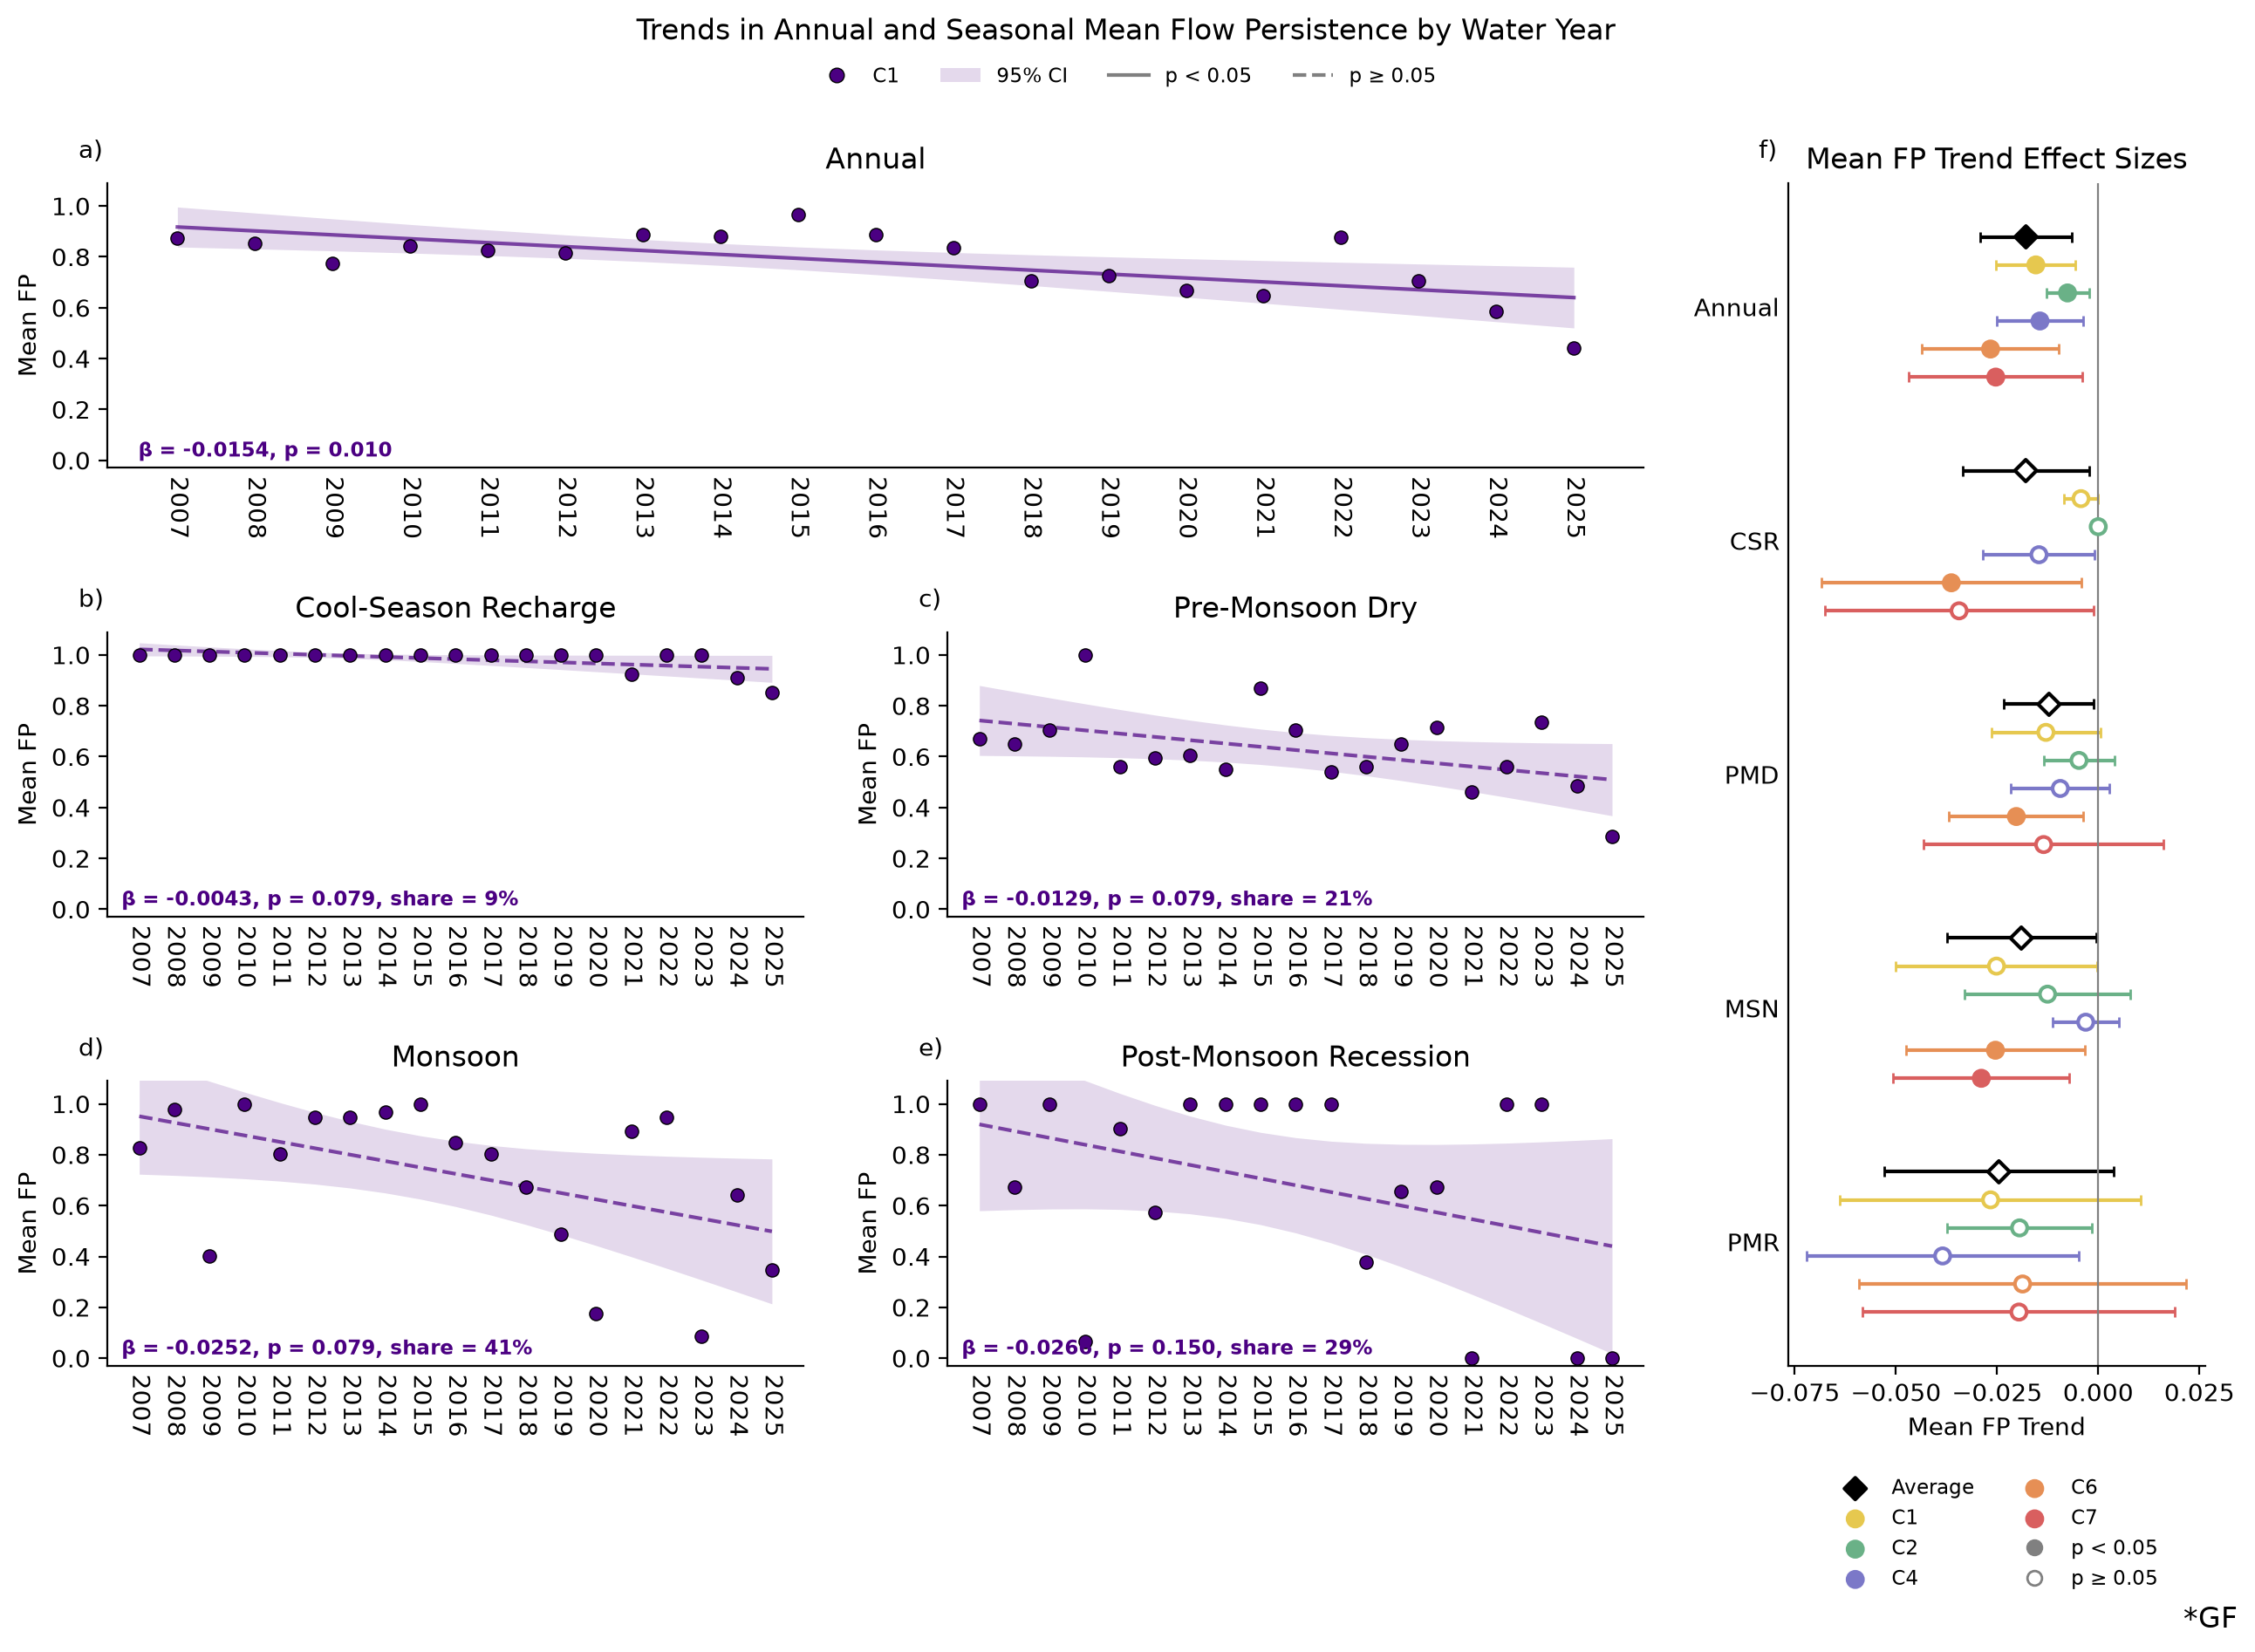

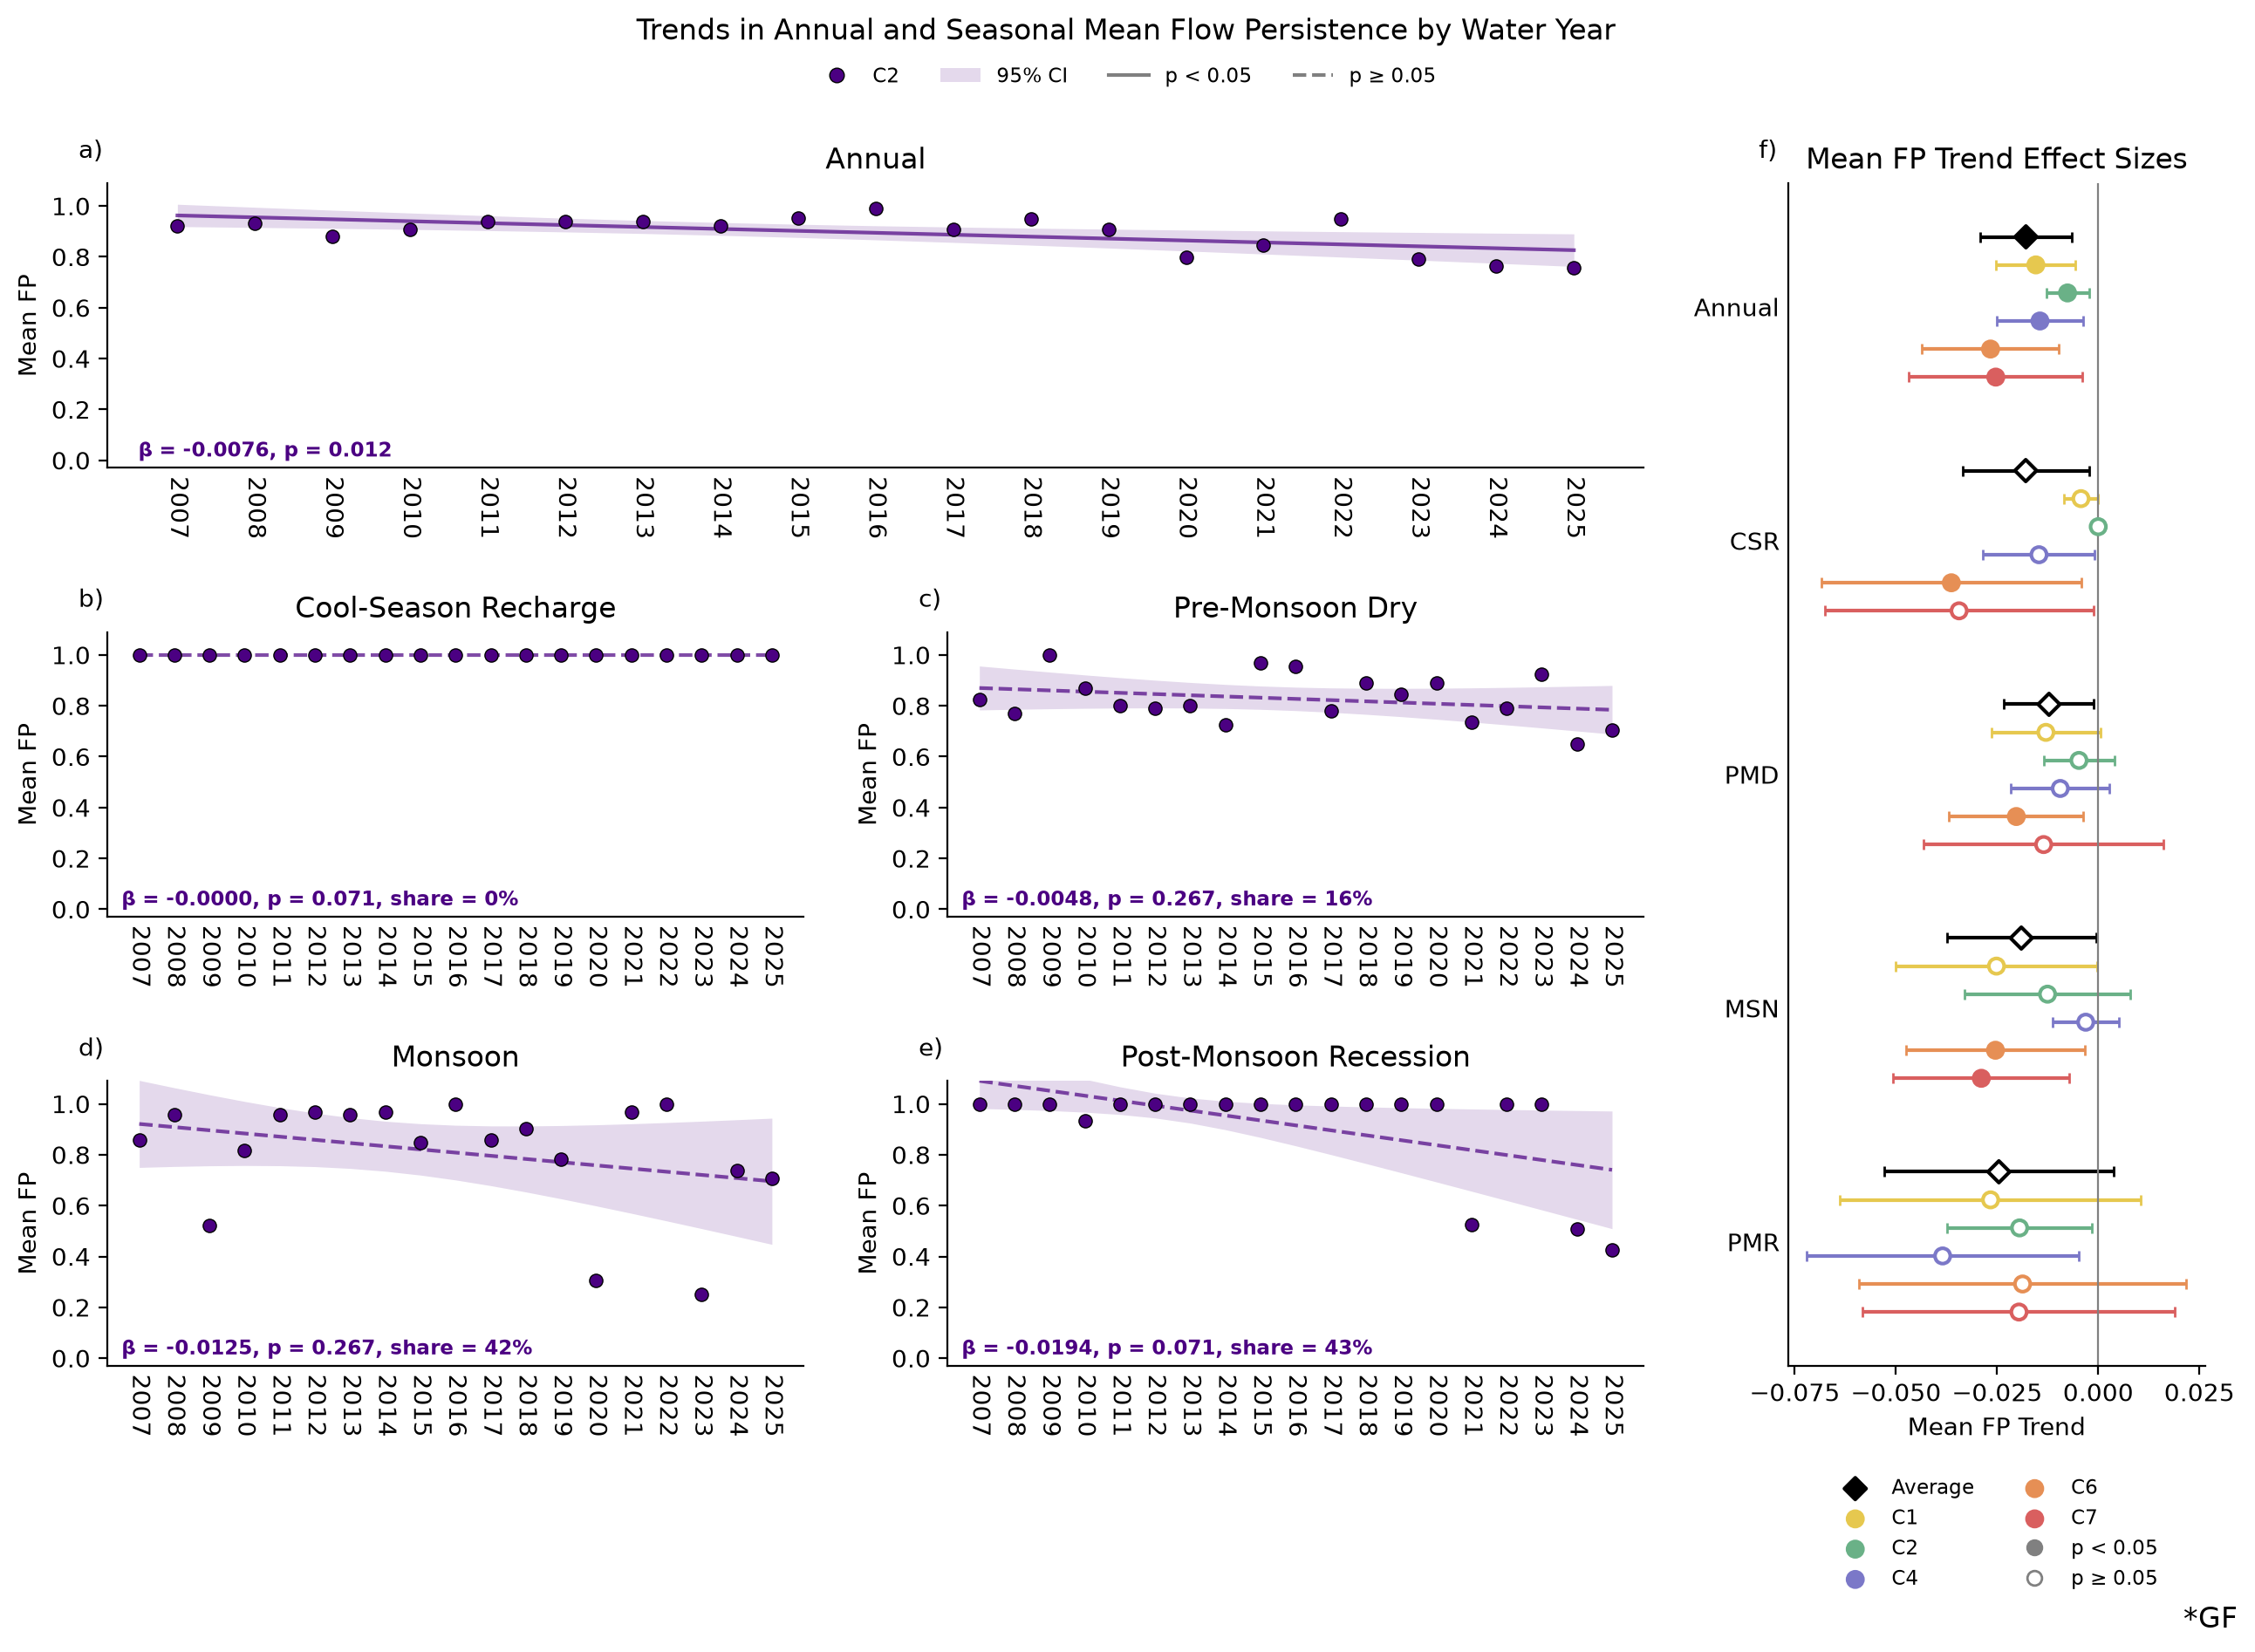

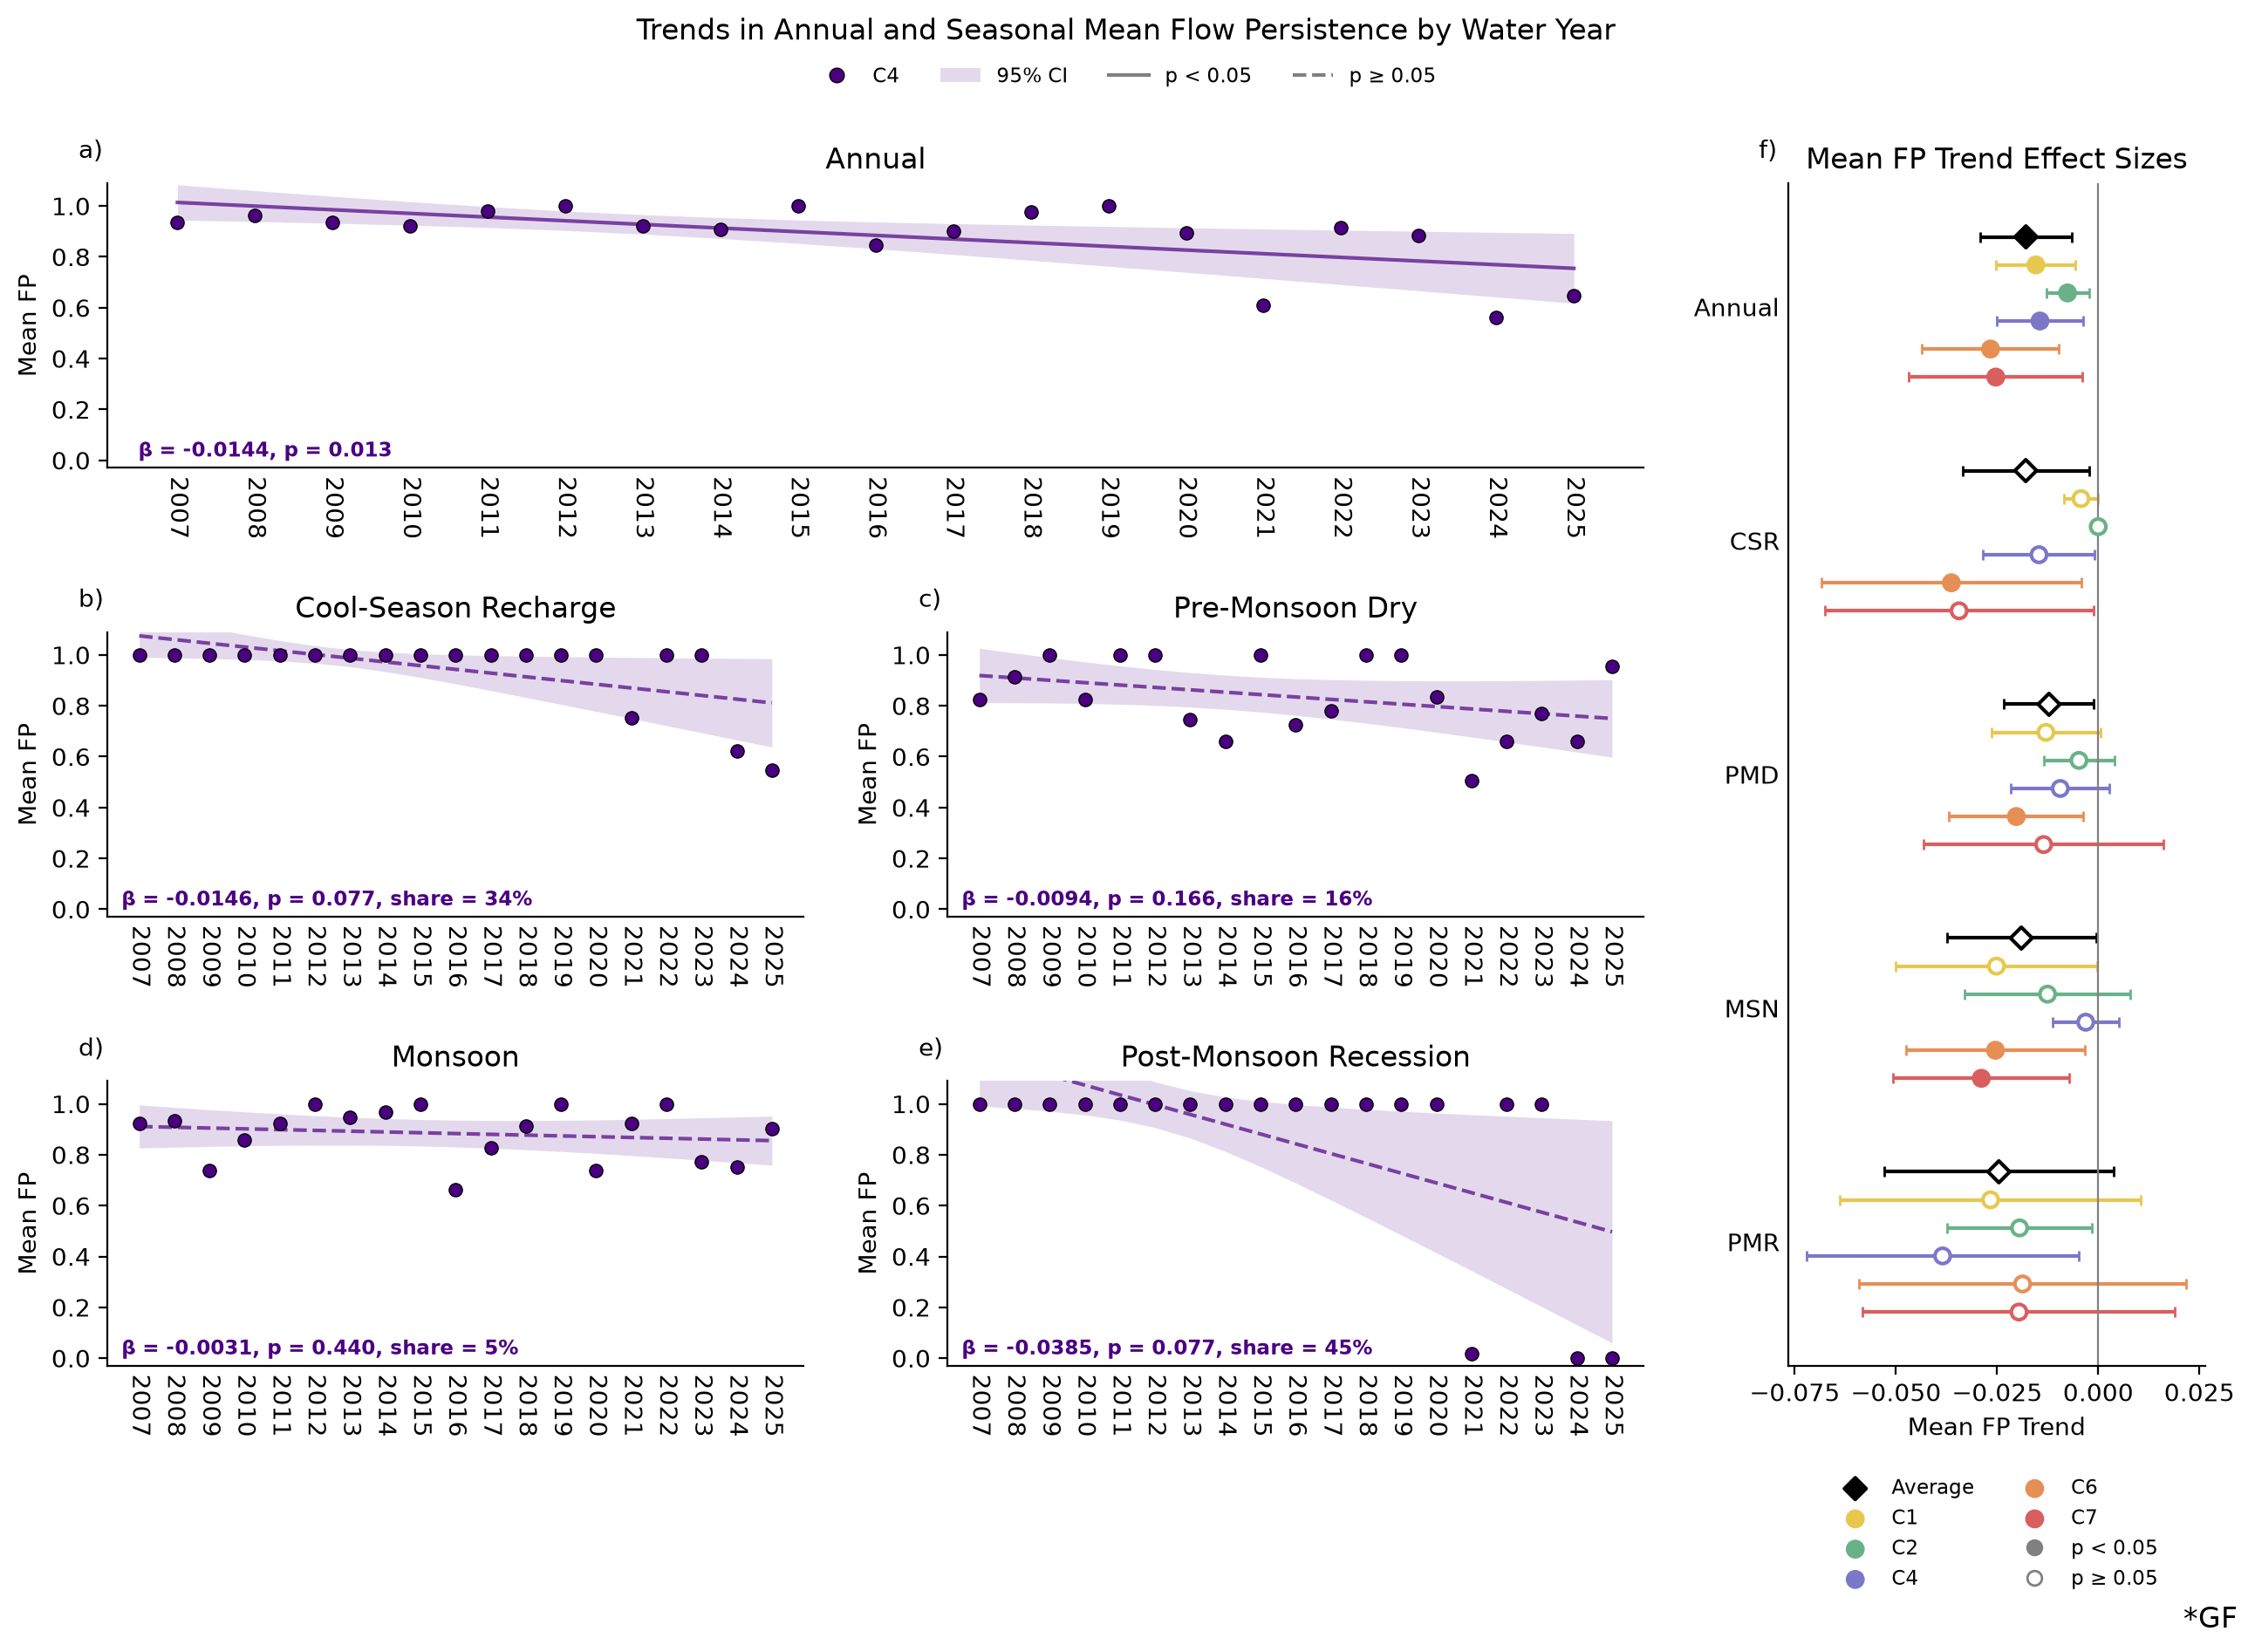

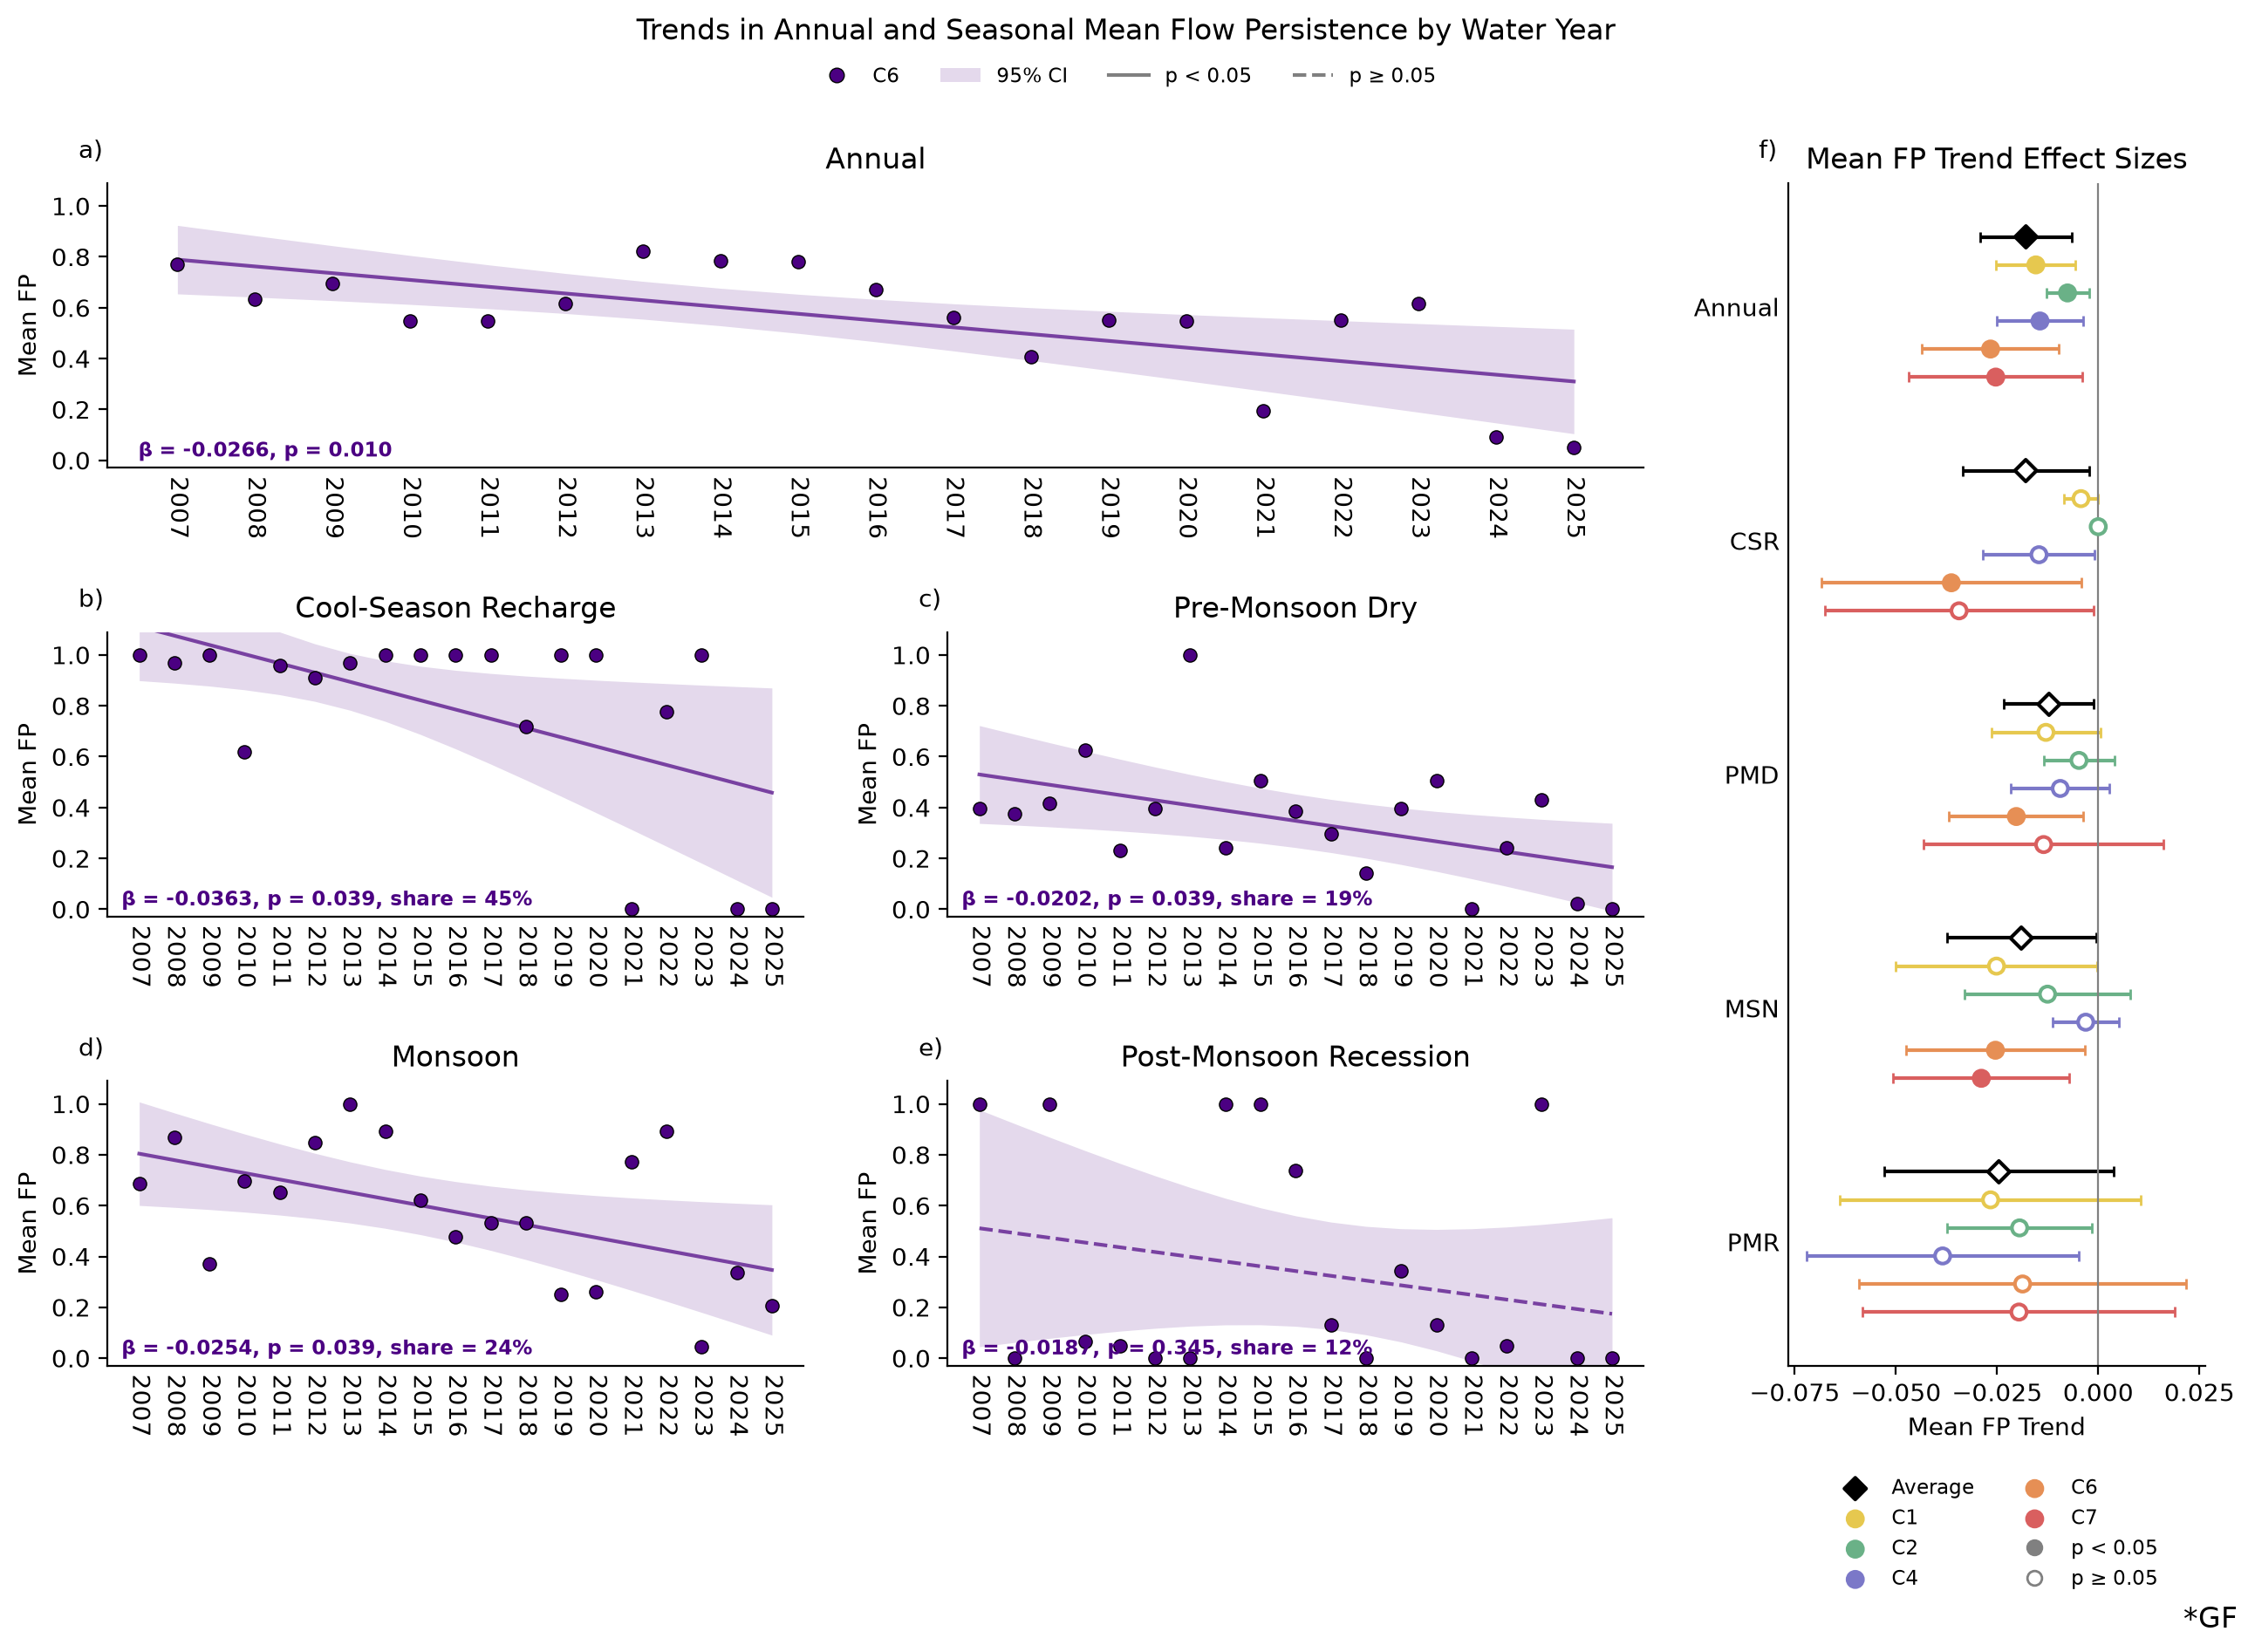

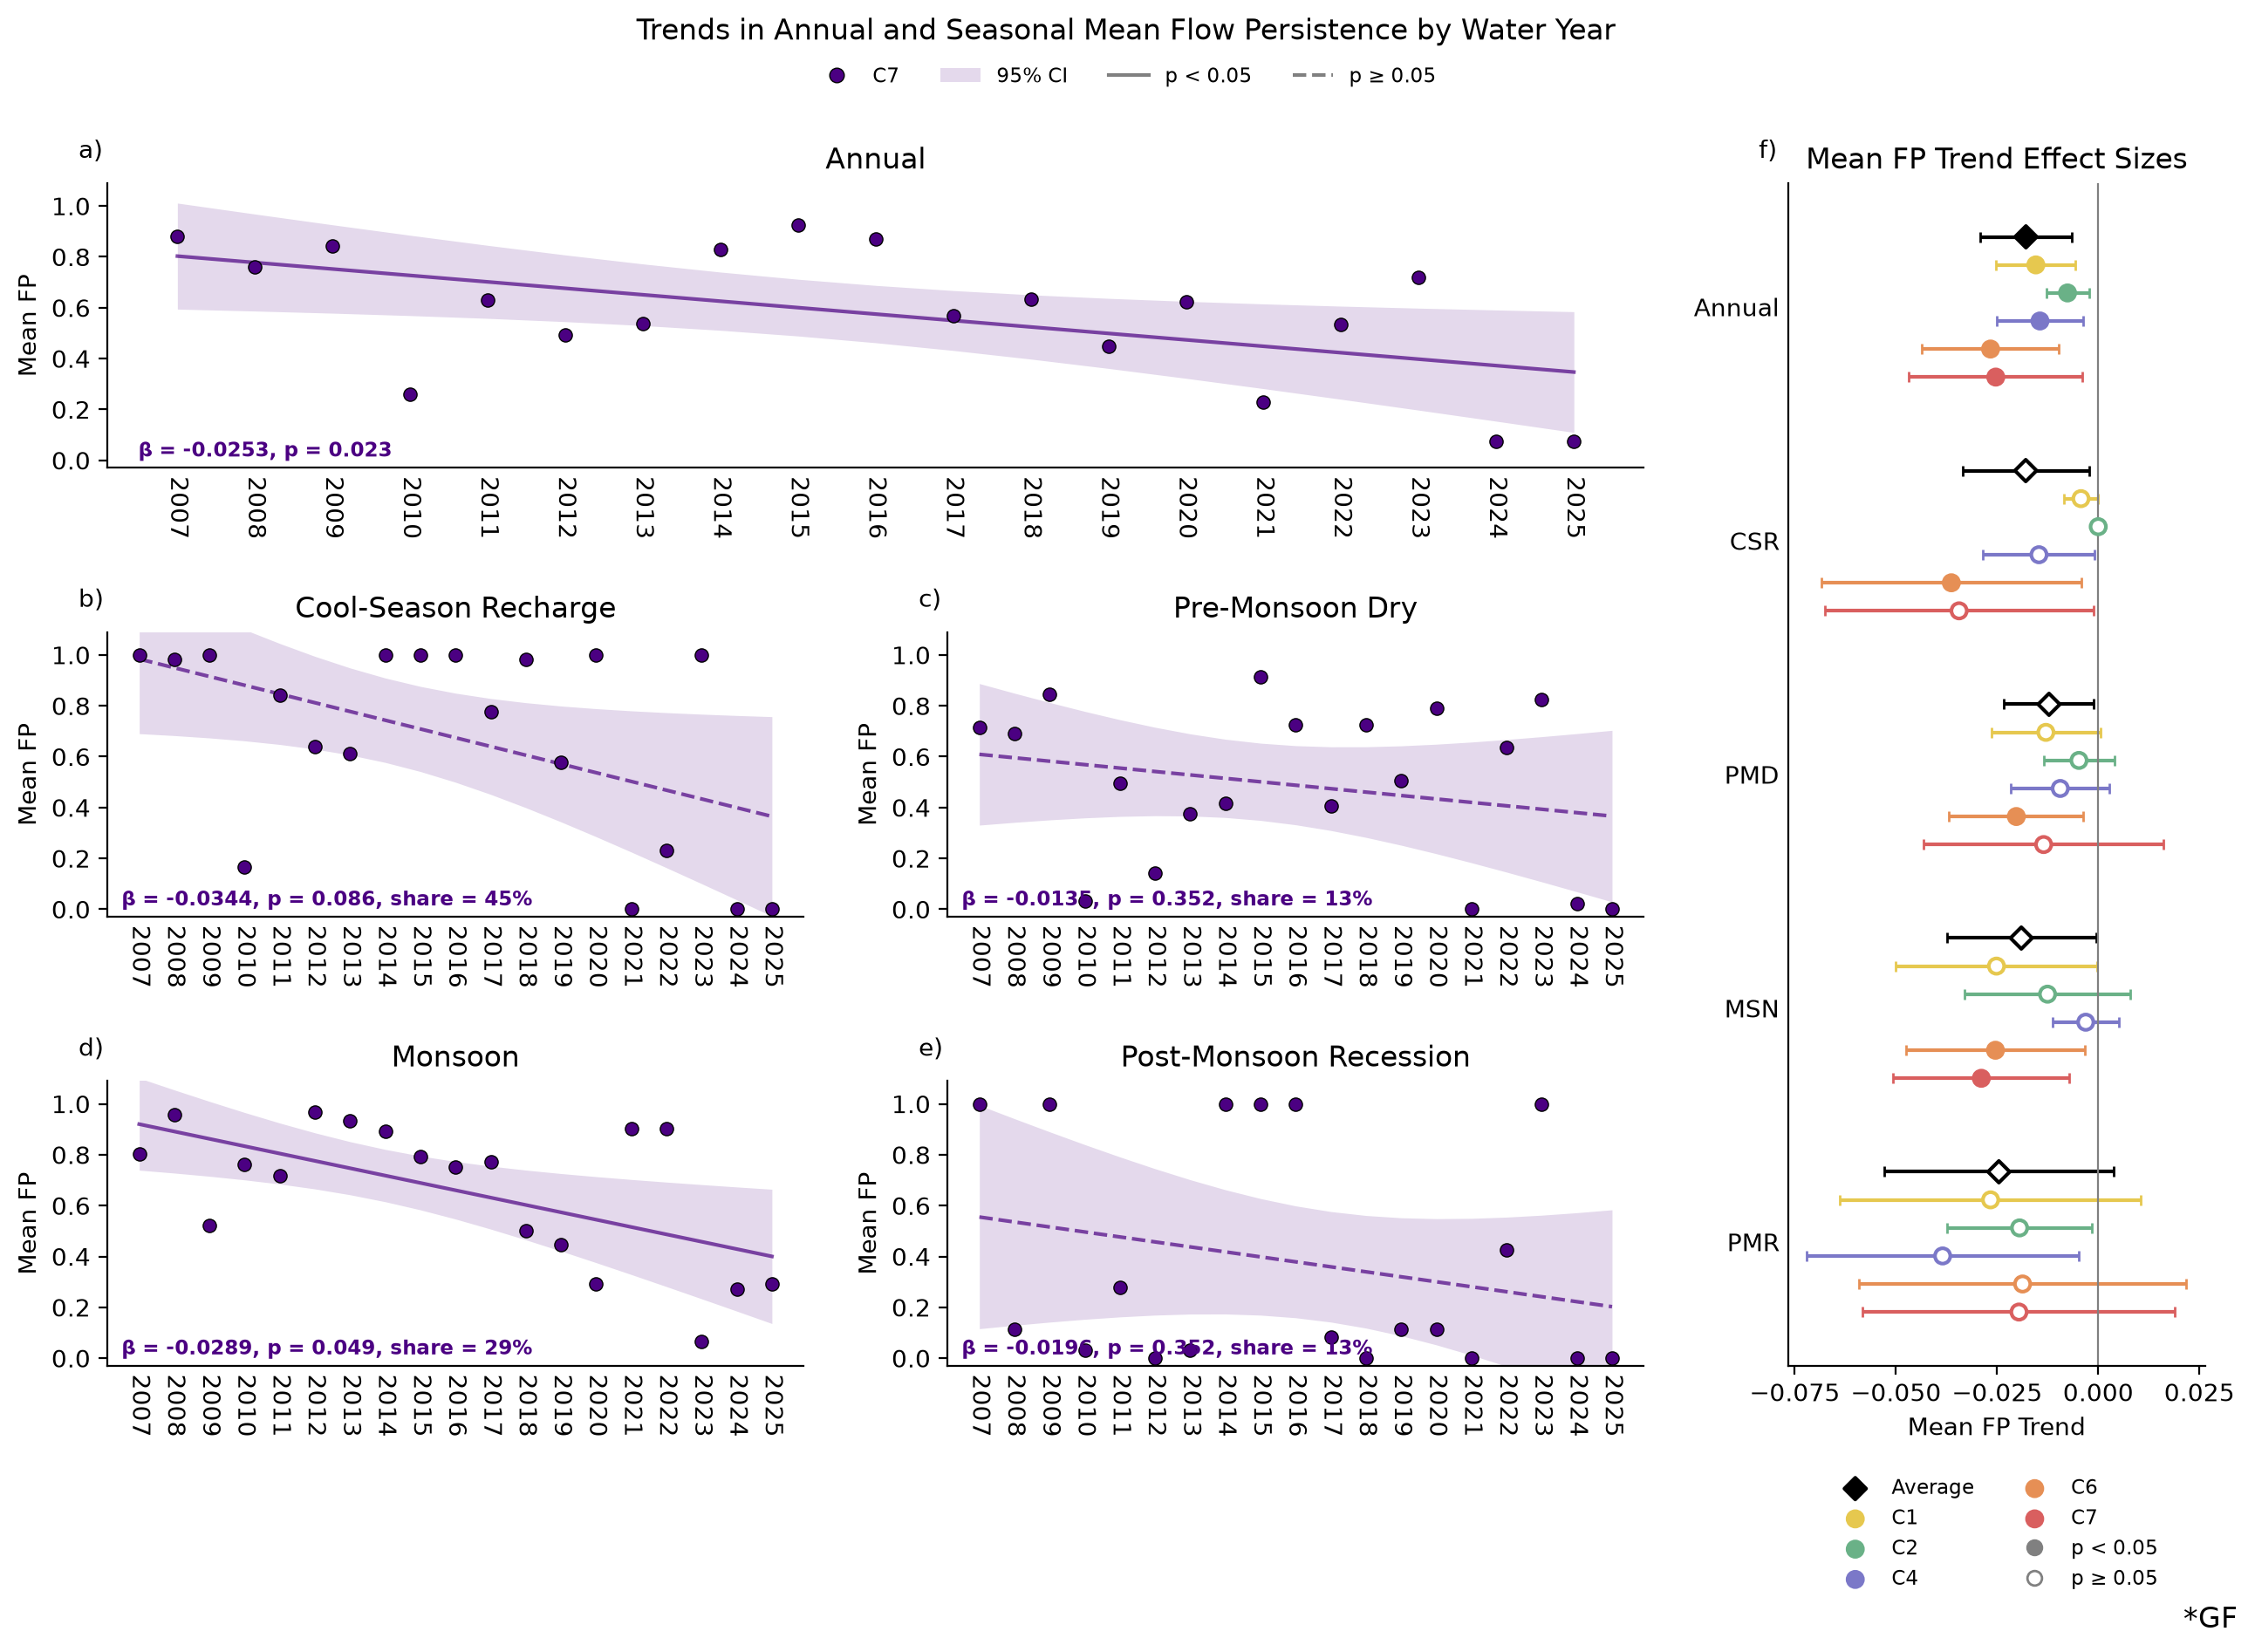

In [9]:
def predict(camera, season_weights, years):
    X = pd.DataFrame(0.0, index = years, columns = model.params.index)
    for s, w in season_weights.items():
        X[f"C(Camera)[{camera}]:C(Season)[{s}]"] += w
        X[f"C(Camera)[{camera}]:C(Season)[{s}]:year_c"] += w * (years - year_mean)
    pred = model.t_test(X.to_numpy())
    ci = pred.conf_int(alpha)
    return pred.effect, ci[:, 0], ci[:, 1]

%config InlineBackend.figure_format = "retina"

for example in perennial:
    fig = plt.figure(figsize = (13, 9))
    gs = fig.add_gridspec(3, 3, width_ratios = [1, 1, 0.6])
    ax0 = fig.add_subplot(gs[0, :2])
    ax1 = fig.add_subplot(gs[1, 0])
    ax2 = fig.add_subplot(gs[1, 1])
    ax3 = fig.add_subplot(gs[2, 0])
    ax4 = fig.add_subplot(gs[2, 1])
    ax5 = fig.add_subplot(gs[:, 2])

    fig.suptitle("Trends in Annual and Seasonal Mean Flow Persistence by Water Year", y = 1.025)

    example_color = "indigo"
    example_effects = effects.loc[f"C{example}"]
    years = np.arange(2007, 2026)

    def plot_trend(ax, data, season_weights, row, show_share):
        ax.scatter(data["WY"], data["FP"], color = example_color, s = 30, edgecolor = "black", linewidth = 0.5, zorder = 3)
        mean, lower, upper = predict(example, season_weights, years)
        ax.fill_between(years, lower, upper, color = example_color, alpha = 0.15, linewidth = 0)
        ax.plot(years, mean, color = example_color, alpha = 0.7, linestyle = "-" if row["p_adj"] < alpha else "--")
        p_text = "p < 0.001" if row["p_adj"] < 0.001 else f"p = {row['p_adj']:.3f}"
        text = f"β = {row['beta']:.4f}, {p_text}"
        if show_share:
            text += f", share = {row['share']:.0%}"
        ax.text(0.02, 0.04, text, transform = ax.transAxes, color = example_color, fontsize = "small", fontweight = "bold")
        ax.spines[["top", "right"]].set_visible(False)
        ax.set_ylabel("Mean FP")
        ax.set_ylim(-0.03, 1.09)
        ax.set_yticks(np.arange(0, 1.01, 0.2))
        ax.set_xticks(years)
        ax.tick_params(axis = "x", length = 0, labelrotation = 270)

    plot_trend(ax0, annual[annual["Camera"] == example], weights.to_dict(), example_effects.loc["Annual"], False)
    ax0.set_title("Annual")

    axes_map = {1: ax1, 2: ax2, 3: ax3, 4: ax4}

    for season_id, ax in axes_map.items():
        data = seasonal[(seasonal["Camera"] == example) & (seasonal["Season"] == season_id)]
        plot_trend(ax, data, {season_id: 1.0}, example_effects.loc[season_id], True)
        ax.set_title(seasons[season_id])

    camera_colors = dict(zip(sites.values(), ["#d95f5f", "#e68f55", "#e6c84f", "#a8c66c", "#6ab187", "#5aa6c8", "#7b78c8", "#b58ac9"]))
    model_colors = {"Average": "black", **{f"C{c}": camera_colors[c] for c in perennial}}
    groups = ["Annual"] + list(seasons)
    offsets = np.linspace(-0.3, 0.3, len(model_colors))

    for offset, (label, color) in zip(offsets, model_colors.items()):
        rows = effects.loc[label].loc[groups]
        y = np.arange(len(groups)) + offset
        ax5.errorbar(
            rows["beta"], y,
            xerr = [rows["beta"] - rows["lower"], rows["upper"] - rows["beta"]],
            fmt = "none", ecolor = color, elinewidth = 1.5, capsize = 2
        )
        ax5.scatter(
            rows["beta"], y,
            marker = "D" if label == "Average" else "o",
            s = 40,
            facecolor = [color if p < alpha else "white" for p in rows["p_adj"]],
            edgecolor = color,
            linewidth = 1.5,
            label = label,
            zorder = 3
        )

    ax5.axvline(0, color = "gray", linewidth = 0.8)
    ax5.set_yticks(range(len(groups)))
    ax5.set_yticklabels(["Annual", "CSR", "PMD", "MSN", "PMR"])
    ax5.tick_params(axis = "y", length = 0)
    ax5.invert_yaxis()
    ax5.set_xlabel("Mean FP Trend")
    ax5.set_title("Mean FP Trend Effect Sizes")
    ax5.spines[["top", "right"]].set_visible(False)

    handles, labels = ax5.get_legend_handles_labels()
    handles += [
        plt.Line2D([], [], marker = "o", color = "gray", linestyle = "none"),
        plt.Line2D([], [], marker = "o", color = "gray", markerfacecolor = "white", linestyle = "none"),
    ]
    labels += [f"p < {alpha}", f"p ≥ {alpha}"]
    ax5.legend(handles, labels, loc = "upper center", bbox_to_anchor = (0.5, -0.08), ncol = 2, fontsize = "small", frameon = False)

    for letter, ax in zip("abcdef", [ax0, ax1, ax2, ax3, ax4, ax5]):
        ax.annotate(
            f"{letter})",
            xy = (0, 1),
            xycoords = "axes fraction",
            xytext = (-12, 8),
            textcoords = "offset points",
            va = "bottom"
        )

    handles = [
        plt.Line2D([], [], marker = "o", color = example_color, markeredgecolor = "black", markeredgewidth = 0.5, linestyle = "none"),
        plt.Rectangle((0, 0), 1, 1, color = example_color, alpha = 0.15, linewidth = 0),
        plt.Line2D([], [], color = "gray", linestyle = "-"),
        plt.Line2D([], [], color = "gray", linestyle = "--"),
    ]
    labels = [f"C{example}", "95% CI", f"p < {alpha}", f"p ≥ {alpha}"]
    fig.legend(
        handles, labels,
        loc = "upper center",
        bbox_to_anchor = (0.5, 1.005),
        ncol = len(handles),
        frameon = False,
        fontsize = "small"
    )

    fig.text(0.99, -0.005, "*GF", ha = "right", va = "bottom", fontsize = "large")

    plt.tight_layout(rect = (0, 0.015, 1, 0.97))
    plt.tight_layout(h_pad = 2, w_pad = 2)

    # plt.savefig(f"../Figures/seasonal_fp_mlr_C{example}.png", format = "png", dpi = 300, bbox_inches = "tight")
    plt.show()